<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
--------------------------------------
Nº Filas y Columnas             (891, 12)
Media de Edad                  29.70 años
Mediana de Edad                28.00 años
Desviación Estándar de Edad         14.53
Edad Máxima                    80.00 años
Edad Mínim

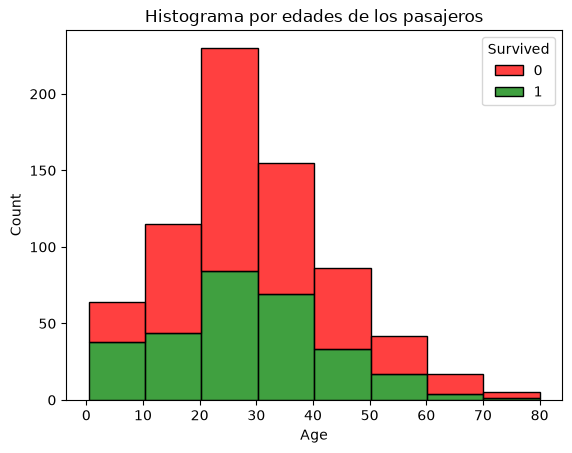

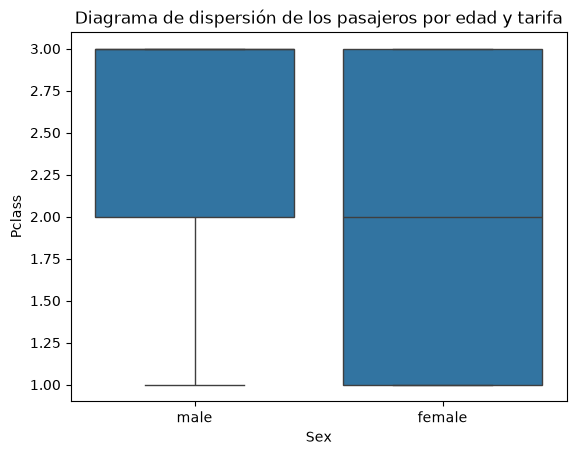

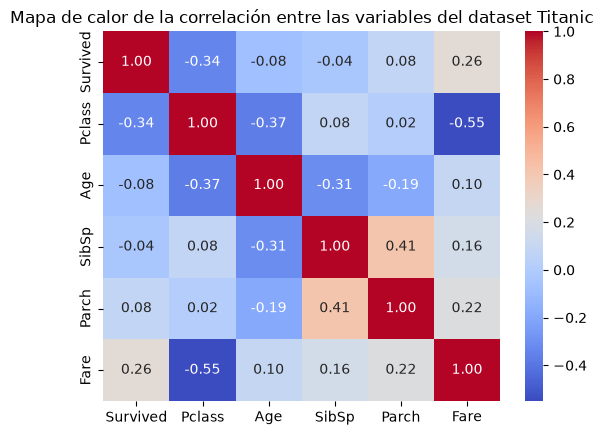

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

# Cargar el dataset de titanic
# NOTA: Jupyter mantiene el dataset en memoria, por lo que no es necesario volver a cargarlo si ya se ha hecho previamente.
if not("titanic" in globals()):
    titanic = pd.read_csv("../data/Titanic-Dataset.csv")

# Número de filas y columnas, 891 pasajeros y 12 columnas.
n_filas_columnas = titanic.shape

# Información de las columnas y tipos de datos.
"""_summary_
int64 not null: 
    PassengerId: Identificador del pasajero,
    Survived: Supervivencia del pasajero,
    Pclass: Clase del pasajero,
    SibSp: Número de hermanos/cónyuges a bordo del pasajero,
    Parch: Número de padres/hijos a bordo del pasajero,
float64 not null: 
    Age: Edad del pasajero,
    Fare: Tarifa pagada por el pasajero,
string not null: 
    Name: Nombre del pasajero,
    Sex: Sexo del pasajero,
    Ticket: Número de ticket del pasajero,
    Cabin: Cabina del pasajero,
    Embarked: Puerto de embarque del pasajero

Posibles valores:
        PassengerId: 1, 2, 3, ...
        Survived: 0 (fallecido), 1 (sobrevivido)
        Pclass: 1, 2, 3
        Name: Rose, Jack, ...
        Sex: male, female
        Age: 0.4, 22.0, 38.0, ...
        SibSp: 0, 1, 2, ...
        Parch: 0, 1, 2, ...
        Ticket: SHIP 1, SHIP 2, ...
        Fare: 7.25, 71.2833, 15.5, ...
        Cabin: A1, A2, B1, ...
        Embarked: A, B, C, ...
"""
titanic.info()

# Información de los datos nulos por columna, 
# Cabin tiene 687 datos null, Age tiene 177 datos null y Embarked tiene 2 datos null.
list_valores_null_filas_5 =titanic.isna().sum().sort_values(ascending=False).head(5)
list_valores_null =titanic.isna().sum().sort_values(ascending=False)

# Media de las edades de los pasajeros.
media_edad = titanic["Age"].mean()
mediana_edad = titanic["Age"].median()
menores_edad = titanic[titanic["Age"] < 18]

max_edad = titanic["Age"].max()
min_edad = titanic["Age"].min()

print("--------------------------------------")
resumen = pd.Series({
    'Nº Filas y Columnas': n_filas_columnas, 
    'Media de Edad': f"{media_edad:.2f} años",
    'Mediana de Edad': f"{mediana_edad:.2f} años",
    'Desviación Estándar de Edad': f"{titanic['Age'].std():.2f}",
    'Edad Máxima': f"{max_edad:.2f} años",
    'Edad Mínima': f"{min_edad:.2f} años",
    'Valores Duplicados': titanic.duplicated().sum(), 
    })
print(resumen)
# print(f"Numero de filas y columnas: {n_filas_columnas}")
# print(f"Media de edad de los pasajeros: {media_edad:.2f} años")
# print(f"Mediana de edad de los pasajeros: {mediana_edad:.2f} años")
# # print(f"Media de los menores de edad: {menores_edad['Age'].mean():.1f} años")
# print(f"STD: Desviación estándar de la edad de los pasajeros: {titanic['Age'].std():.2f}")
# print(f"Edad máxima de los pasajeros: {max_edad:.2f} años")
# print(f"Edad mínima de los pasajeros: {min_edad:.2f} años")
# print(f"Valores duplicados en el dataset: {titanic.duplicated().sum()}")

for columna, nulos in list_valores_null_filas_5.items():
    if nulos > 0:
        print(f"{columna}: {nulos} datos nulos")

for columna, nulos in list_valores_null.items():
    if nulos > 0:
        print(f"{columna}: {nulos} datos nulos")

# Estadística descriptiva de la columna Age.
# Todo lo anterior en una sola línea de código.
titanic["Age"].describe().round(2)

# Gráfico de supervivencia de los pasajeros por genero.
sex = ["male", "female"]
survived = titanic[titanic["Survived"] == 1].groupby(titanic["Sex"]).count()
print(survived["Sex"])

# Histograma por edades de los pasajeros, con un binwidth de 10 años, diferencido por color la supervivencia de los pasajeros.
sns.histplot(data=titanic, x="Age", binwidth=10, hue="Survived", multiple="stack", palette={0: "red", 1: "green"}, element="bars")
plt.title("Histograma por edades de los pasajeros")
plt.show()

# Diagrama de disperción de los pasajeros por edad y tarifa.
sns.boxplot(data=titanic, x="Sex", y="Pclass")
plt.title("Diagrama de dispersión de los pasajeros por edad y tarifa")
plt.show()



correlacion_titanic = titanic.drop(columns=["PassengerId"]).corr(numeric_only=True)
sns.heatmap(data=correlacion_titanic, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Mapa de calor de la correlación entre las variables del dataset Titanic")
plt.show()